# 🔬 Ракурсы и достаточность Small

**Вопрос:** помогает ли разнообразие видов приблизить лёгкую MobileNetV3-Small к Large?

Для мобильного приложения важны качество и вычислительная стоимость. Проверяем их
раздельно. Модель приложения и прежний notebook09 не меняем.

---
## 🎯 Гипотеза и правила решения

**О** — только основной вид. **Р** — main/left/right поровну при том же N каждого POI.
Четыре конфигурации × seeds42,43,44 = **12 обучений**.

`GО = F(Large,О) − F(Small,О)`; `GР = F(Large,Р) − F(Small,Р)`; `C = GО − GР`.
F — среднее test Macro-F1 трёх классификаторов, не ансамбль.

✅ Поддержка: lower95(C)≥0.03 **и** upper95(GР)≤0.03.
❌ Порог не достигнут: upper95(C)<0.03 либо lower95(GР)>0.03.
❔ Пересечение границ или отсутствие допустимого интервала: неопределённый результат.
Отсутствие разницы не доказывает допустимое отставание.

Источник: [дизайн исследования](https://chatgpt.com/space/page_c6e1f387570c8191b2e0b23740308af7).
Снимок исходного дизайна сохранён рядом с manifests.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'src/viewpoint_training.py').exists()
sys.path.insert(0, str(ROOT))
from IPython.display import display, Markdown, Image, HTML
import html
from src.viewpoint_audit import read, folders
from src.viewpoint_reporting import table, run_display
DATA, REPORT, MODELS, RUNTIME = folders(ROOT)
def show_csv(path, columns=None): display(Markdown(table(read(path), columns)))
def show_json(path): display(HTML('<details><summary>'+html.escape(path.name)+'</summary><pre>'+html.escape(path.read_text(encoding='utf-8'))+'</pre></details>'))
TRAIN = False  # По умолчанию показываем артефакты: повторного обучения нет.


## 🗂️ EDA и визуальная разметка

Полный каталог проверен до метрик. Визуальный reviewer — `codex_visual_review`;
второй независимой человеческой проверки нет. Кроп/яркость/дистанция не создают новый
ракурс. Для неоднозначной стороны — `undetermined`.

Все исходные фото неизменны. Исторические val/test и связанная прогулка не входят в train.
Сведения source/author/licence сохранены; неизвестные значения не додумываются.

| poi_id | train | val | test | excluded |
| --- | --- | --- | --- | --- |
| moscow/arbat/arseny_morozov_house | 26 | 8 | 14 | 0 |
| moscow/arbat/pashkov_house | 15 | 16 | 19 | 0 |
| moscow/khamovniki/khrushchev_seleznev_house | 15 | 8 | 10 | 0 |
| moscow/khamovniki/pushkin_museum | 14 | 10 | 14 | 0 |
| moscow/ostankinskiy/armenia | 108 | 36 | 56 | 0 |
| moscow/ostankinskiy/central_pavilion | 72 | 16 | 116 | 0 |
| moscow/ostankinskiy/cosmos | 58 | 26 | 32 | 0 |
| moscow/ostankinskiy/friendship_of_the_peoples | 27 | 10 | 13 | 0 |
| moscow/ostankinskiy/kazakhstan_pavilion | 81 | 18 | 129 | 0 |
| moscow/ostankinskiy/main_entrance | 21 | 21 | 127 | 1 |
| moscow/ostankinskiy/moldova_pavilion | 55 | 14 | 25 | 0 |
| moscow/ostankinskiy/moscow_sun | 29 | 10 | 23 | 0 |
| moscow/ostankinskiy/moskvarium | 8 | 2 | 2 | 0 |
| moscow/ostankinskiy/ostankino_tower | 35 | 13 | 25 | 0 |
| moscow/ostankinskiy/pavilion_5 | 4 | 1 | 79 | 0 |
| moscow/ostankinskiy/pavilion_71 | 43 | 12 | 49 | 0 |
| moscow/ostankinskiy/polymer_house | 7 | 2 | 2 | 0 |
| moscow/ostankinskiy/robostation | 7 | 12 | 124 | 0 |
| moscow/ostankinskiy/stone_flower | 16 | 4 | 3 | 0 |
| moscow/tverskoy/bolshoi_theatre | 15 | 8 | 27 | 0 |
| moscow/tverskoy/hotel_metropol | 20 | 3 | 20 | 0 |
| moscow/tverskoy/hotel_national | 10 | 2 | 4 | 0 |
| moscow/tverskoy/maly_theatre | 14 | 5 | 4 | 0 |

| poi_id | main | left | right | undetermined | unreviewed |
| --- | --- | --- | --- | --- | --- |
| moscow/arbat/arseny_morozov_house | 11 | 5 | 2 | 8 | 0 |
| moscow/arbat/pashkov_house | 7 | 3 | 1 | 4 | 0 |
| moscow/khamovniki/khrushchev_seleznev_house | 4 | 1 | 0 | 10 | 0 |
| moscow/khamovniki/pushkin_museum | 5 | 2 | 2 | 5 | 0 |
| moscow/ostankinskiy/armenia | 54 | 3 | 23 | 28 | 0 |
| moscow/ostankinskiy/central_pavilion | 37 | 9 | 6 | 20 | 0 |
| moscow/ostankinskiy/cosmos | 10 | 2 | 3 | 43 | 0 |
| moscow/ostankinskiy/friendship_of_the_peoples | 2 | 0 | 0 | 25 | 0 |
| moscow/ostankinskiy/kazakhstan_pavilion | 25 | 12 | 20 | 24 | 0 |
| moscow/ostankinskiy/main_entrance | 8 | 1 | 2 | 10 | 0 |
| moscow/ostankinskiy/moldova_pavilion | 28 | 14 | 9 | 4 | 0 |
| moscow/ostankinskiy/moscow_sun | 5 | 0 | 0 | 24 | 0 |
| moscow/ostankinskiy/moskvarium | 4 | 0 | 1 | 3 | 0 |
| moscow/ostankinskiy/ostankino_tower | 3 | 0 | 0 | 32 | 0 |
| moscow/ostankinskiy/pavilion_5 | 3 | 0 | 0 | 1 | 0 |
| moscow/ostankinskiy/pavilion_71 | 19 | 5 | 6 | 13 | 0 |
| moscow/ostankinskiy/polymer_house | 5 | 1 | 0 | 1 | 0 |
| moscow/ostankinskiy/robostation | 2 | 1 | 0 | 4 | 0 |
| moscow/ostankinskiy/stone_flower | 2 | 0 | 0 | 14 | 0 |
| moscow/tverskoy/bolshoi_theatre | 9 | 1 | 2 | 3 | 0 |
| moscow/tverskoy/hotel_metropol | 3 | 0 | 6 | 11 | 0 |
| moscow/tverskoy/hotel_national | 4 | 1 | 4 | 1 | 0 |
| moscow/tverskoy/maly_theatre | 2 | 7 | 1 | 4 | 0 |

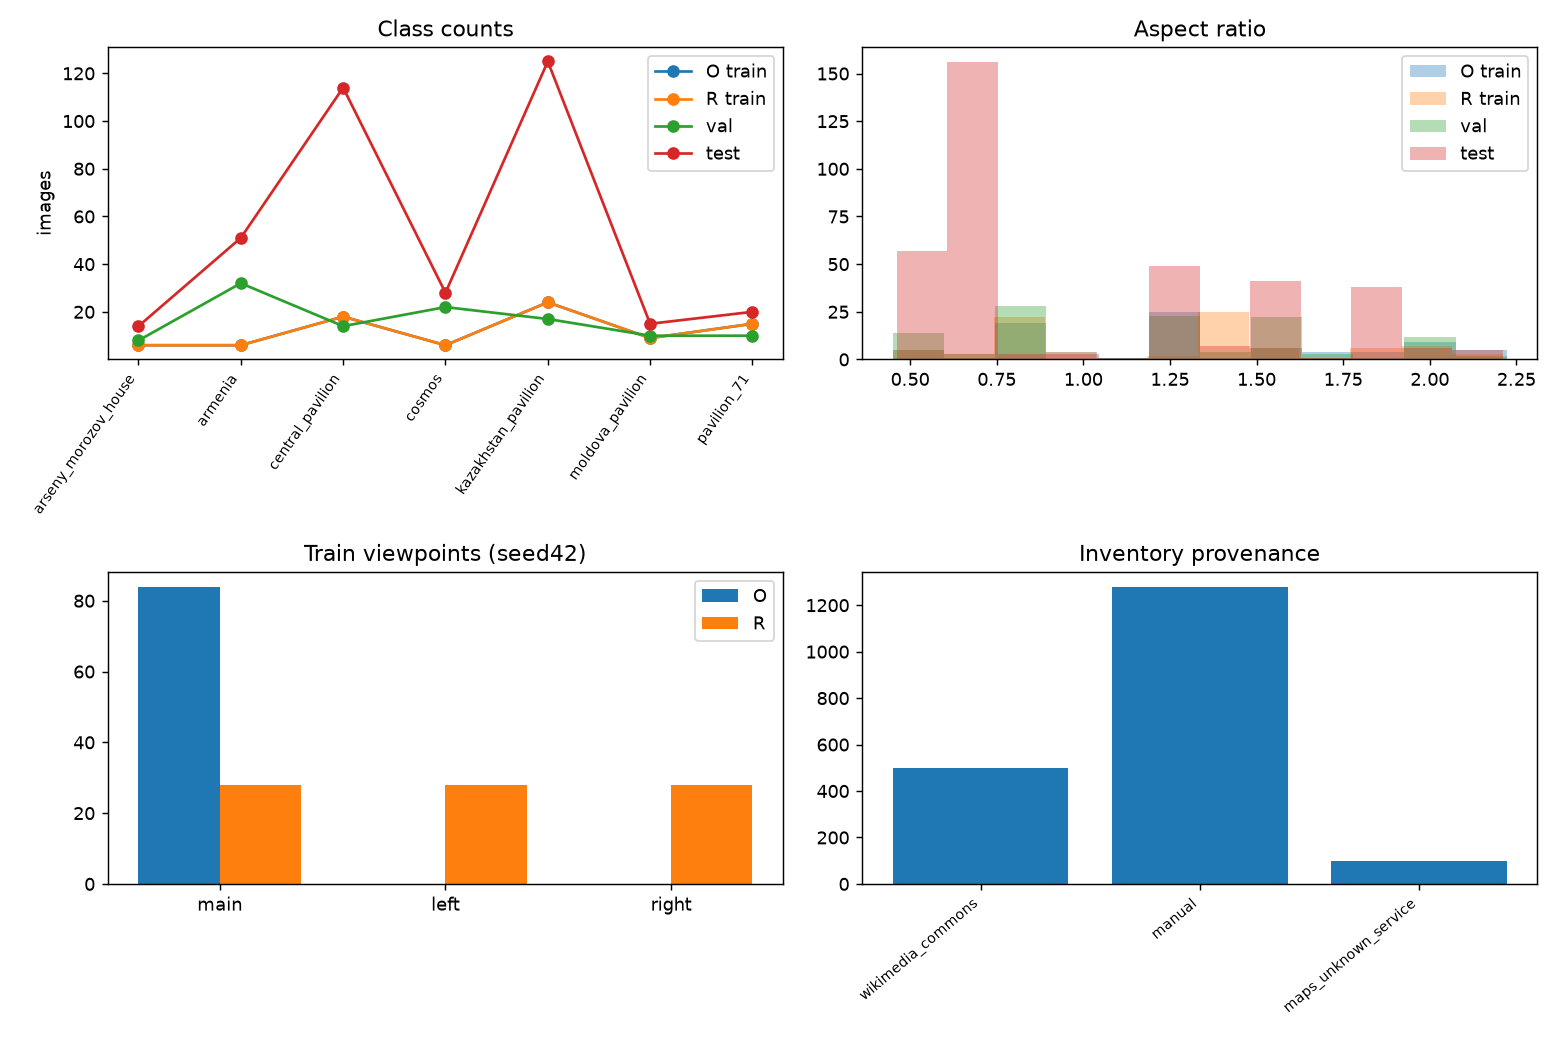

In [2]:
show_csv(REPORT / 'reconciled_coverage.csv')
show_csv(REPORT / 'viewpoint_coverage.csv')
display(Image(filename=str(REPORT/'figures/eda.png')))

In [3]:
show_csv(REPORT / 'included_pois.csv')
show_csv(REPORT / 'excluded_pois.csv')

| poi_id | N |
| --- | --- |
| moscow/arbat/arseny_morozov_house | 6 |
| moscow/ostankinskiy/armenia | 6 |
| moscow/ostankinskiy/central_pavilion | 18 |
| moscow/ostankinskiy/cosmos | 6 |
| moscow/ostankinskiy/kazakhstan_pavilion | 24 |
| moscow/ostankinskiy/moldova_pavilion | 9 |
| moscow/ostankinskiy/pavilion_71 | 15 |

| poi_id | main | left | right | reason |
| --- | --- | --- | --- | --- |
| moscow/arbat/pashkov_house | 7 | 3 | 1 | Не хватает минимум 6 основных + 2 левых + 2 правых разных семей при точном балансе источников и TV<=0.20 по свету/масштабу/перекрытиям, либо ракурсы не установлены. |
| moscow/khamovniki/khrushchev_seleznev_house | 4 | 1 | 0 | Не хватает минимум 6 основных + 2 левых + 2 правых разных семей при точном балансе источников и TV<=0.20 по свету/масштабу/перекрытиям, либо ракурсы не установлены. |
| moscow/khamovniki/pushkin_museum | 5 | 2 | 2 | Не хватает минимум 6 основных + 2 левых + 2 правых разных семей при точном балансе источников и TV<=0.20 по свету/масштабу/перекрытиям, либо ракурсы не установлены. |
| moscow/ostankinskiy/friendship_of_the_peoples | 2 | 0 | 0 | Не хватает минимум 6 основных + 2 левых + 2 правых разных семей при точном балансе источников и TV<=0.20 по свету/масштабу/перекрытиям, либо ракурсы не установлены. |
| moscow/ostankinskiy/main_entrance | 8 | 1 | 2 | Не хватает минимум 6 основных + 2 левых + 2 правых разных семей при точном балансе источников и TV<=0.20 по свету/масштабу/перекрытиям, либо ракурсы не установлены. |
| moscow/ostankinskiy/moscow_sun | 5 | 0 | 0 | Не хватает минимум 6 основных + 2 левых + 2 правых разных семей при точном балансе источников и TV<=0.20 по свету/масштабу/перекрытиям, либо ракурсы не установлены. |
| moscow/ostankinskiy/moskvarium | 4 | 0 | 1 | Не хватает минимум 6 основных + 2 левых + 2 правых разных семей при точном балансе источников и TV<=0.20 по свету/масштабу/перекрытиям, либо ракурсы не установлены. |
| moscow/ostankinskiy/ostankino_tower | 3 | 0 | 0 | Не хватает минимум 6 основных + 2 левых + 2 правых разных семей при точном балансе источников и TV<=0.20 по свету/масштабу/перекрытиям, либо ракурсы не установлены. |
| moscow/ostankinskiy/pavilion_5 | 3 | 0 | 0 | Не хватает минимум 6 основных + 2 левых + 2 правых разных семей при точном балансе источников и TV<=0.20 по свету/масштабу/перекрытиям, либо ракурсы не установлены. |
| moscow/ostankinskiy/polymer_house | 5 | 1 | 0 | Не хватает минимум 6 основных + 2 левых + 2 правых разных семей при точном балансе источников и TV<=0.20 по свету/масштабу/перекрытиям, либо ракурсы не установлены. |
| moscow/ostankinskiy/robostation | 2 | 1 | 0 | Не хватает минимум 6 основных + 2 левых + 2 правых разных семей при точном балансе источников и TV<=0.20 по свету/масштабу/перекрытиям, либо ракурсы не установлены. |
| moscow/ostankinskiy/stone_flower | 2 | 0 | 0 | Не хватает минимум 6 основных + 2 левых + 2 правых разных семей при точном балансе источников и TV<=0.20 по свету/масштабу/перекрытиям, либо ракурсы не установлены. |
| moscow/tverskoy/bolshoi_theatre | 9 | 1 | 2 | Не хватает минимум 6 основных + 2 левых + 2 правых разных семей при точном балансе источников и TV<=0.20 по свету/масштабу/перекрытиям, либо ракурсы не установлены. |
| moscow/tverskoy/hotel_metropol | 3 | 0 | 6 | Не хватает минимум 6 основных + 2 левых + 2 правых разных семей при точном балансе источников и TV<=0.20 по свету/масштабу/перекрытиям, либо ракурсы не установлены. |
| moscow/tverskoy/hotel_national | 4 | 1 | 4 | Не хватает минимум 6 основных + 2 левых + 2 правых разных семей при точном балансе источников и TV<=0.20 по свету/масштабу/перекрытиям, либо ракурсы не установлены. |
| moscow/tverskoy/maly_theatre | 2 | 7 | 1 | Не хватает минимум 6 основных + 2 левых + 2 правых разных семей при точном балансе источников и TV<=0.20 по свету/масштабу/перекрытиям, либо ракурсы не установлены. |

In [4]:
cards=json.loads((DATA/'orientation_cards.json').read_text(encoding='utf-8'))
included={r['poi_id'] for r in read(REPORT/'included_pois.csv')}
display(Markdown(table([{'poi_id':r['poi_id'],'main':r['main'],'left':r['left'],'right':r['right']} for r in cards if r['poi_id'] in included])))

| poi_id | main | left | right |
| --- | --- | --- | --- |
| moscow/arbat/arseny_morozov_house | Ось арочного входа между двумя круглыми башенками с каменной резьбой; фронтальный вид входного портала. | Со стороны левого крыла: длинная стена тянется влево от ближней башни, портал виден справа в перспективе. | Со стороны правой башни/правого крыла: ближе правая башня, портал уходит влево. |
| moscow/ostankinskiy/armenia | Фронтальный главный портик с надписью АРМЕНИЯ и скульптурами над колоннами; боковая стена не задаёт направление. | Камера слева от оси главного портика: видна его левая боковая арка/стена слева, надпись уходит вправо в перспективе. | Камера справа от оси портика: фасад слева, арочная боковая стена и продольное крыло уходят вправо. |
| moscow/ostankinskiy/central_pavilion | Ось главного входа с памятником Ленину перед центральной колоннадой и многоярусной башней со шпилем; фронтальная симметрия. | Камера слева от оси главного фасада: видна длинная левая боковая стена, главный портик смещён вправо. | Камера справа от оси: видна правая глухая боковая стена/крыло справа, колоннада обращена влево. |
| moscow/ostankinskiy/cosmos | Главный арочный стеклянный фасад с двумя башнями и надписью Космос/СССР, со стороны ракеты; купольный противоположный торец не является этим фасадом. | Слева от оси арочного входа: левая башня ближе, боковая часть павильона видна слева, арочная плоскость уходит вправо. | Справа от оси арочного входа: правая башня ближе, боковой объём виден справа, плоскость арки уходит влево. |
| moscow/ostankinskiy/kazakhstan_pavilion | Фронтальный фасад с тремя арочными проёмами, сине-белым орнаментом и куполом; обе плоские крыловые части сопоставимы. | Камера слева от оси орнаментального входа: ближе левая плоская часть с надписью на казахском, арочный центр уходит вправо. | Камера справа: ближе правое крыло с надписью КАЗАХСКАЯ ССР, арочный центр смещён влево. |
| moscow/ostankinskiy/moldova_pavilion | Главный жёлтый фасад с надписью МОЛДОВА, гербом и центральной дверью; фронтальная колоннада без выраженного бокового ухода. | Вид слева от главного входа: ближняя левая глухая жёлтая часть перед колоннадой; карниз уходит вниз вправо. | Вид справа: ближняя правая жёлтая часть/правая колонна, колоннада уходит влево; карниз поднимается вправо. |
| moscow/ostankinskiy/pavilion_71 | Главный высокий портик с гербом и шестью колоннами, симметричные боковые круглые входы; фасад без выраженного ухода. | Камера слева от оси главного портика: ближе левый ряд колонн, фронтальная плоскость уходит вправо. | Камера справа: видна правая торцевая стена с окнами и табличкой Мои документы; колоннада уходит влево. |

### Сопоставимость О/Р

N выбирается из 24,21,18,15,12,9,6; в Р каждого вида N/3. Источники совпадают точно.
Для света/масштаба/перекрытий TV≤0.20 (сначала пробуем точные совместные страты).
Поэтому сравнение не объявляется чистым причинным эффектом ракурса.
Правило, каталог, manifests, bootstrap-схема и SHA зафиксированы до обучения.

In [5]:
show_json(DATA / 'selection_rule.json')
show_csv(REPORT / 'selection_balance.csv')

| poi_id | seed | mode | images | known_sessions | unknown_session_images | source | illumination | scale | occlusion | viewpoint |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| moscow/arbat/arseny_morozov_house | 42 | O | 6 | 4 | 2 | {"wikimedia_commons": 6} | {"day": 6} | {"medium": 3, "whole": 3} | {"medium": 1, "low": 5} | {"main": 6} |
| moscow/arbat/arseny_morozov_house | 42 | R | 6 | 3 | 3 | {"wikimedia_commons": 6} | {"day": 6} | {"medium": 3, "whole": 3} | {"medium": 1, "low": 5} | {"main": 2, "left": 2, "right": 2} |
| moscow/ostankinskiy/armenia | 42 | O | 6 | 0 | 6 | {"manual": 4, "maps_unknown_service": 2} | {"day": 6} | {"medium": 4, "whole": 2} | {"low": 6} | {"main": 6} |
| moscow/ostankinskiy/armenia | 42 | R | 6 | 0 | 6 | {"manual": 4, "maps_unknown_service": 2} | {"day": 6} | {"medium": 3, "whole": 3} | {"low": 6} | {"main": 2, "right": 2, "left": 2} |
| moscow/ostankinskiy/central_pavilion | 42 | O | 18 | 3 | 15 | {"manual": 15, "wikimedia_commons": 3} | {"day": 15, "backlit": 1, "night": 1, "twilight": 1} | {"whole": 15, "medium": 3} | {"low": 13, "medium": 5} | {"main": 18} |
| moscow/ostankinskiy/central_pavilion | 42 | R | 18 | 3 | 15 | {"manual": 15, "wikimedia_commons": 3} | {"day": 15, "night": 3} | {"whole": 18} | {"low": 16, "medium": 2} | {"main": 6, "right": 6, "left": 6} |
| moscow/ostankinskiy/cosmos | 42 | O | 6 | 0 | 6 | {"manual": 6} | {"day": 5, "night": 1} | {"whole": 4, "medium": 2} | {"low": 5, "medium": 1} | {"main": 6} |
| moscow/ostankinskiy/cosmos | 42 | R | 6 | 0 | 6 | {"manual": 6} | {"day": 5, "night": 1} | {"whole": 5, "medium": 1} | {"low": 6} | {"main": 2, "right": 2, "left": 2} |
| moscow/ostankinskiy/kazakhstan_pavilion | 42 | O | 24 | 0 | 24 | {"manual": 24} | {"day": 22, "backlit": 1, "night": 1} | {"whole": 18, "medium": 6} | {"low": 22, "medium": 2} | {"main": 24} |
| moscow/ostankinskiy/kazakhstan_pavilion | 42 | R | 24 | 0 | 24 | {"manual": 24} | {"day": 22, "twilight": 1, "night": 1} | {"whole": 21, "medium": 3} | {"low": 21, "medium": 3} | {"main": 8, "right": 8, "left": 8} |
| moscow/ostankinskiy/moldova_pavilion | 42 | O | 9 | 0 | 9 | {"manual": 5, "maps_unknown_service": 4} | {"night": 1, "day": 8} | {"whole": 4, "medium": 5} | {"low": 9} | {"main": 9} |
| moscow/ostankinskiy/moldova_pavilion | 42 | R | 9 | 0 | 9 | {"manual": 5, "maps_unknown_service": 4} | {"day": 7, "night": 2} | {"medium": 4, "whole": 5} | {"low": 8, "medium": 1} | {"right": 3, "main": 3, "left": 3} |
| moscow/ostankinskiy/pavilion_71 | 42 | O | 15 | 0 | 15 | {"manual": 15} | {"day": 13, "night": 2} | {"whole": 12, "medium": 3} | {"low": 14, "medium": 1} | {"main": 15} |
| moscow/ostankinskiy/pavilion_71 | 42 | R | 15 | 0 | 15 | {"manual": 15} | {"night": 3, "day": 12} | {"medium": 5, "whole": 10} | {"low": 15} | {"left": 5, "main": 5, "right": 5} |
| moscow/arbat/arseny_morozov_house | 43 | O | 6 | 4 | 1 | {"wikimedia_commons": 6} | {"day": 6} | {"whole": 5, "medium": 1} | {"medium": 2, "low": 4} | {"main": 6} |
| moscow/arbat/arseny_morozov_house | 43 | R | 6 | 5 | 1 | {"wikimedia_commons": 6} | {"day": 5, "twilight": 1} | {"whole": 4, "medium": 2} | {"medium": 1, "low": 5} | {"main": 2, "right": 2, "left": 2} |
| moscow/ostankinskiy/armenia | 43 | O | 6 | 0 | 6 | {"manual": 4, "maps_unknown_service": 2} | {"day": 6} | {"whole": 4, "medium": 2} | {"low": 6} | {"main": 6} |
| moscow/ostankinskiy/armenia | 43 | R | 6 | 0 | 6 | {"manual": 4, "maps_unknown_service": 2} | {"day": 6} | {"whole": 4, "medium": 2} | {"low": 6} | {"main": 2, "left": 2, "right": 2} |
| moscow/ostankinskiy/central_pavilion | 43 | O | 18 | 2 | 16 | {"manual": 16, "wikimedia_commons": 2} | {"day": 13, "backlit": 1, "night": 3, "twilight": 1} | {"whole": 15, "medium": 3} | {"low": 14, "medium": 4} | {"main": 18} |
| moscow/ostankinskiy/central_pavilion | 43 | R | 18 | 2 | 16 | {"manual": 16, "wikimedia_commons": 2} | {"night": 5, "day": 13} | {"whole": 18} | {"low": 17, "medium": 1} | {"right": 6, "left": 6, "main": 6} |
| moscow/ostankinskiy/cosmos | 43 | O | 6 | 0 | 6 | {"manual": 6} | {"day": 5, "night": 1} | {"whole": 4, "medium": 2} | {"low": 5, "medium": 1} | {"main": 6} |
| moscow/ostankinskiy/cosmos | 43 | R | 6 | 0 | 6 | {"manual": 6} | {"twilight": 1, "night": 1, "day": 4} | {"whole": 5, "medium": 1} | {"low": 5, "medium": 1} | {"right": 2, "main": 2, "left": 2} |
| moscow/ostankinskiy/kazakhstan_pavilion | 43 | O | 24 | 0 | 24 | {"manual": 24} | {"day": 22, "backlit": 1, "night": 1} | {"whole": 18, "medium": 6} | {"low": 22, "medium": 2} | {"main": 24} |
| moscow/ostankinskiy/kazakhstan_pavilion | 43 | R | 24 | 0 | 24 | {"manual": 24} | {"day": 22, "night": 2} | {"medium": 4, "whole": 20} | {"low": 22, "medium": 2} | {"main": 8, "left": 8, "right": 8} |
| moscow/ostankinskiy/moldova_pavilion | 43 | O | 9 | 0 | 9 | {"manual": 6, "maps_unknown_service": 3} | {"day": 6, "night": 3} | {"medium": 5, "whole": 4} | {"low": 9} | {"main": 9} |
| moscow/ostankinskiy/moldova_pavilion | 43 | R | 9 | 0 | 9 | {"manual": 6, "maps_unknown_service": 3} | {"day": 5, "night": 4} | {"medium": 5, "whole": 4} | {"low": 8, "medium": 1} | {"right": 3, "main": 3, "left": 3} |
| moscow/ostankinskiy/pavilion_71 | 43 | O | 15 | 0 | 15 | {"manual": 15} | {"day": 13, "night": 2} | {"whole": 13, "medium": 2} | {"low": 14, "medium": 1} | {"main": 15} |
| moscow/ostankinskiy/pavilion_71 | 43 | R | 15 | 0 | 15 | {"manual": 15} | {"night": 4, "day": 11} | {"medium": 5, "whole": 10} | {"low": 15} | {"left": 5, "main": 5, "right": 5} |
| moscow/arbat/arseny_morozov_house | 44 | O | 6 | 3 | 3 | {"wikimedia_commons": 6} | {"day": 6} | {"medium": 2, "whole": 4} | {"medium": 1, "low": 5} | {"main": 6} |
| moscow/arbat/arseny_morozov_house | 44 | R | 6 | 4 | 2 | {"wikimedia_commons": 6} | {"day": 6} | {"medium": 3, "whole": 3} | {"medium": 1, "low": 5} | {"main": 2, "left": 2, "right": 2} |
| moscow/ostankinskiy/armenia | 44 | O | 6 | 1 | 5 | {"manual": 2, "maps_unknown_service": 3, "wikimedia_commons": 1} | {"twilight": 1, "day": 5} | {"whole": 3, "medium": 3} | {"low": 5, "medium": 1} | {"main": 6} |
| moscow/ostankinskiy/armenia | 44 | R | 6 | 1 | 5 | {"manual": 2, "maps_unknown_service": 3, "wikimedia_commons": 1} | {"twilight": 1, "day": 5} | {"whole": 4, "medium": 2} | {"low": 5, "medium": 1} | {"main": 2, "left": 2, "right": 2} |
| moscow/ostankinskiy/central_pavilion | 44 | O | 18 | 2 | 16 | {"manual": 16, "wikimedia_commons": 2} | {"backlit": 1, "day": 13, "night": 3, "twilight": 1} | {"whole": 15, "medium": 3} | {"low": 14, "medium": 4} | {"main": 18} |
| moscow/ostankinskiy/central_pavilion | 44 | R | 18 | 2 | 16 | {"manual": 16, "wikimedia_commons": 2} | {"day": 14, "night": 4} | {"whole": 17, "medium": 1} | {"medium": 2, "low": 16} | {"main": 6, "right": 6, "left": 6} |
| moscow/ostankinskiy/cosmos | 44 | O | 6 | 0 | 6 | {"manual": 6} | {"day": 5, "night": 1} | {"whole": 4, "medium": 2} | {"low": 5, "medium": 1} | {"main": 6} |
| moscow/ostankinskiy/cosmos | 44 | R | 6 | 0 | 6 | {"manual": 6} | {"twilight": 1, "night": 1, "day": 4} | {"whole": 5, "medium": 1} | {"low": 6} | {"right": 2, "left": 2, "main": 2} |
| moscow/ostankinskiy/kazakhstan_pavilion | 44 | O | 24 | 0 | 24 | {"manual": 24} | {"day": 22, "backlit": 1, "night": 1} | {"whole": 17, "medium": 7} | {"low": 22, "medium": 2} | {"main": 24} |
| moscow/ostankinskiy/kazakhstan_pavilion | 44 | R | 24 | 0 | 24 | {"manual": 24} | {"day": 23, "night": 1} | {"whole": 20, "medium": 4} | {"low": 23, "medium": 1} | {"main": 8, "left": 8, "right": 8} |
| moscow/ostankinskiy/moldova_pavilion | 44 | O | 9 | 0 | 9 | {"manual": 7, "maps_unknown_service": 2} | {"day": 7, "night": 2} | {"medium": 6, "whole": 3} | {"low": 9} | {"main": 9} |
| moscow/ostankinskiy/moldova_pavilion | 44 | R | 9 | 0 | 9 | {"manual": 7, "maps_unknown_service": 2} | {"day": 6, "night": 3} | {"medium": 5, "whole": 4} | {"low": 8, "medium": 1} | {"right": 3, "main": 3, "left": 3} |
| moscow/ostankinskiy/pavilion_71 | 44 | O | 15 | 0 | 15 | {"manual": 15} | {"day": 14, "night": 1} | {"whole": 13, "medium": 2} | {"low": 15} | {"main": 15} |
| moscow/ostankinskiy/pavilion_71 | 44 | R | 15 | 0 | 15 | {"manual": 15} | {"night": 4, "day": 11} | {"medium": 5, "whole": 10} | {"low": 15} | {"left": 5, "main": 5, "right": 5} |

In [6]:
show_csv(REPORT / 'manifest_viewpoint_coverage.csv')
show_json(REPORT / 'integrity_before_training.json')

| manifest | poi_id | images | undetermined | main | left | right |
| --- | --- | --- | --- | --- | --- | --- |
| test | moscow/arbat/arseny_morozov_house | 14 | 4 | 3 | 6 | 1 |
| test | moscow/ostankinskiy/armenia | 51 | 4 | 34 |  | 13 |
| test | moscow/ostankinskiy/central_pavilion | 114 | 38 | 55 | 9 | 12 |
| test | moscow/ostankinskiy/cosmos | 28 | 20 | 5 | 2 | 1 |
| test | moscow/ostankinskiy/kazakhstan_pavilion | 125 | 66 | 15 | 15 | 29 |
| test | moscow/ostankinskiy/moldova_pavilion | 15 |  | 10 | 3 | 2 |
| test | moscow/ostankinskiy/pavilion_71 | 20 |  | 11 | 1 | 8 |
| train_O_seed42 | moscow/arbat/arseny_morozov_house | 6 |  | 6 |  |  |
| train_O_seed42 | moscow/ostankinskiy/armenia | 6 |  | 6 |  |  |
| train_O_seed42 | moscow/ostankinskiy/central_pavilion | 18 |  | 18 |  |  |
| train_O_seed42 | moscow/ostankinskiy/cosmos | 6 |  | 6 |  |  |
| train_O_seed42 | moscow/ostankinskiy/kazakhstan_pavilion | 24 |  | 24 |  |  |
| train_O_seed42 | moscow/ostankinskiy/moldova_pavilion | 9 |  | 9 |  |  |
| train_O_seed42 | moscow/ostankinskiy/pavilion_71 | 15 |  | 15 |  |  |
| train_O_seed43 | moscow/arbat/arseny_morozov_house | 6 |  | 6 |  |  |
| train_O_seed43 | moscow/ostankinskiy/armenia | 6 |  | 6 |  |  |
| train_O_seed43 | moscow/ostankinskiy/central_pavilion | 18 |  | 18 |  |  |
| train_O_seed43 | moscow/ostankinskiy/cosmos | 6 |  | 6 |  |  |
| train_O_seed43 | moscow/ostankinskiy/kazakhstan_pavilion | 24 |  | 24 |  |  |
| train_O_seed43 | moscow/ostankinskiy/moldova_pavilion | 9 |  | 9 |  |  |
| train_O_seed43 | moscow/ostankinskiy/pavilion_71 | 15 |  | 15 |  |  |
| train_O_seed44 | moscow/arbat/arseny_morozov_house | 6 |  | 6 |  |  |
| train_O_seed44 | moscow/ostankinskiy/armenia | 6 |  | 6 |  |  |
| train_O_seed44 | moscow/ostankinskiy/central_pavilion | 18 |  | 18 |  |  |
| train_O_seed44 | moscow/ostankinskiy/cosmos | 6 |  | 6 |  |  |
| train_O_seed44 | moscow/ostankinskiy/kazakhstan_pavilion | 24 |  | 24 |  |  |
| train_O_seed44 | moscow/ostankinskiy/moldova_pavilion | 9 |  | 9 |  |  |
| train_O_seed44 | moscow/ostankinskiy/pavilion_71 | 15 |  | 15 |  |  |
| train_R_seed42 | moscow/arbat/arseny_morozov_house | 6 |  | 2 | 2 | 2 |
| train_R_seed42 | moscow/ostankinskiy/armenia | 6 |  | 2 | 2 | 2 |
| train_R_seed42 | moscow/ostankinskiy/central_pavilion | 18 |  | 6 | 6 | 6 |
| train_R_seed42 | moscow/ostankinskiy/cosmos | 6 |  | 2 | 2 | 2 |
| train_R_seed42 | moscow/ostankinskiy/kazakhstan_pavilion | 24 |  | 8 | 8 | 8 |
| train_R_seed42 | moscow/ostankinskiy/moldova_pavilion | 9 |  | 3 | 3 | 3 |
| train_R_seed42 | moscow/ostankinskiy/pavilion_71 | 15 |  | 5 | 5 | 5 |
| train_R_seed43 | moscow/arbat/arseny_morozov_house | 6 |  | 2 | 2 | 2 |
| train_R_seed43 | moscow/ostankinskiy/armenia | 6 |  | 2 | 2 | 2 |
| train_R_seed43 | moscow/ostankinskiy/central_pavilion | 18 |  | 6 | 6 | 6 |
| train_R_seed43 | moscow/ostankinskiy/cosmos | 6 |  | 2 | 2 | 2 |
| train_R_seed43 | moscow/ostankinskiy/kazakhstan_pavilion | 24 |  | 8 | 8 | 8 |
| train_R_seed43 | moscow/ostankinskiy/moldova_pavilion | 9 |  | 3 | 3 | 3 |
| train_R_seed43 | moscow/ostankinskiy/pavilion_71 | 15 |  | 5 | 5 | 5 |
| train_R_seed44 | moscow/arbat/arseny_morozov_house | 6 |  | 2 | 2 | 2 |
| train_R_seed44 | moscow/ostankinskiy/armenia | 6 |  | 2 | 2 | 2 |
| train_R_seed44 | moscow/ostankinskiy/central_pavilion | 18 |  | 6 | 6 | 6 |
| train_R_seed44 | moscow/ostankinskiy/cosmos | 6 |  | 2 | 2 | 2 |
| train_R_seed44 | moscow/ostankinskiy/kazakhstan_pavilion | 24 |  | 8 | 8 | 8 |
| train_R_seed44 | moscow/ostankinskiy/moldova_pavilion | 9 |  | 3 | 3 | 3 |
| train_R_seed44 | moscow/ostankinskiy/pavilion_71 | 15 |  | 5 | 5 | 5 |
| val | moscow/arbat/arseny_morozov_house | 8 |  | 1 | 7 |  |
| val | moscow/ostankinskiy/armenia | 32 | 8 | 15 |  | 9 |
| val | moscow/ostankinskiy/central_pavilion | 14 | 2 | 8 | 3 | 1 |
| val | moscow/ostankinskiy/cosmos | 22 | 17 | 4 |  | 1 |
| val | moscow/ostankinskiy/kazakhstan_pavilion | 17 | 5 | 3 | 4 | 5 |
| val | moscow/ostankinskiy/moldova_pavilion | 10 | 3 | 3 | 2 | 2 |
| val | moscow/ostankinskiy/pavilion_71 | 10 |  | 7 | 2 | 1 |

### Контактные листы и исходники

Все 700 train-кадров: `reports/viewpoint_20261102_v1/figures/train_final`.
Контрольные кадры: `figures/heldout_selected`; просмотренные оригиналы: `figures/original_checks`.
Ниже примеры выбранных и неопределённых видов. CSV индексы связывают плитки с image_id.

In [7]:
for name in ['selected_O_seed42_01.jpg','selected_R_seed42_01.jpg','undetermined_01.jpg']:
    path=REPORT/'figures'/name
    if path.exists(): display(Image(filename=str(path)))

Фотографии отображаются при локальном Run All; байты фото не сохраняются внутри notebook. Полные контактные листы и их индексы находятся в `figures/`.

---
## ⚙️ Рецепт и четыре пилота

ImageNetV1, RGB224, FP32; все слои и BN обучаются. AdamW1e-4, wd1e-4,
batch32,20 эпох. Class-balanced sampler, CE; только цветовые аугментации.
Максимум validation Macro-F1; при равенстве ранняя эпоха.
После четырёх seed42 пилотов проверяем development-сходимость и ресурсы.
Один и тот же manifest режима используется Small и Large.

In [8]:
show_json(DATA / 'final_config.json')
show_json(REPORT / 'environment.json')

## 🧪 Seed 42 — пилот, входит в 12 при неизменном рецепте

### small · O · seed 42

| config | seed | status | epochs | best_epoch | val_macro_f1 | val_accuracy |
| --- | --- | --- | --- | --- | --- | --- |
| small_O | 42 | complete | 20 | 18 | 0.4752 | 0.4779 |

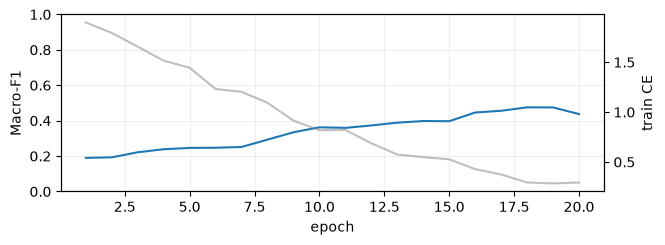

In [9]:
if TRAIN:
    from src.viewpoint_training import fit
    fit(ROOT, 'small', 'O', 42)
run_display(ROOT, 'small_O', 42)

### large · O · seed 42

| config | seed | status | epochs | best_epoch | val_macro_f1 | val_accuracy |
| --- | --- | --- | --- | --- | --- | --- |
| large_O | 42 | complete | 20 | 14 | 0.5524 | 0.5575 |

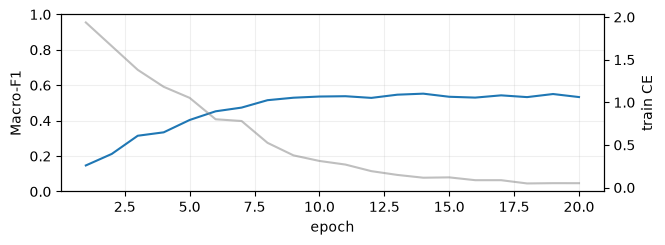

In [10]:
if TRAIN:
    from src.viewpoint_training import fit
    fit(ROOT, 'large', 'O', 42)
run_display(ROOT, 'large_O', 42)

### small · R · seed 42

| config | seed | status | epochs | best_epoch | val_macro_f1 | val_accuracy |
| --- | --- | --- | --- | --- | --- | --- |
| small_R | 42 | complete | 20 | 19 | 0.4480 | 0.4867 |

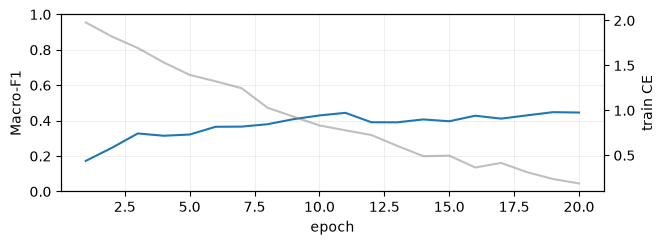

In [11]:
if TRAIN:
    from src.viewpoint_training import fit
    fit(ROOT, 'small', 'R', 42)
run_display(ROOT, 'small_R', 42)

### large · R · seed 42

| config | seed | status | epochs | best_epoch | val_macro_f1 | val_accuracy |
| --- | --- | --- | --- | --- | --- | --- |
| large_R | 42 | complete | 20 | 19 | 0.5328 | 0.5398 |

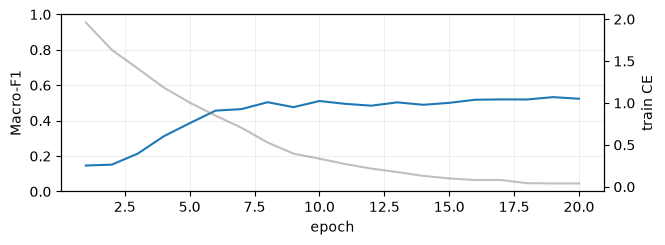

In [12]:
if TRAIN:
    from src.viewpoint_training import fit
    fit(ROOT, 'large', 'R', 42)
run_display(ROOT, 'large_R', 42)

In [13]:
show_csv(REPORT / 'pilot_review.csv')
show_json(REPORT / 'pilot_decision.json')

| architecture | mode | epochs | best_epoch | val_macro_f1 | last_loss | tail_f1_gain | training_seconds | convergence_warning |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| small | O | 20 | 18 | 0.4752 | 0.2944 | -0.0088 | 59.4070 | False |
| small | R | 20 | 19 | 0.4480 | 0.1871 | 0.0180 | 60.7680 | False |
| large | O | 20 | 14 | 0.5524 | 0.0516 | 0.0030 | 175.6430 | False |
| large | R | 20 | 19 | 0.5328 | 0.0402 | 0.0057 | 168.7800 | False |

## 🧪 Seed 43 — основной план

### small · O · seed 43

| config | seed | status | epochs | best_epoch | val_macro_f1 | val_accuracy |
| --- | --- | --- | --- | --- | --- | --- |
| small_O | 43 | complete | 20 | 16 | 0.5291 | 0.5310 |

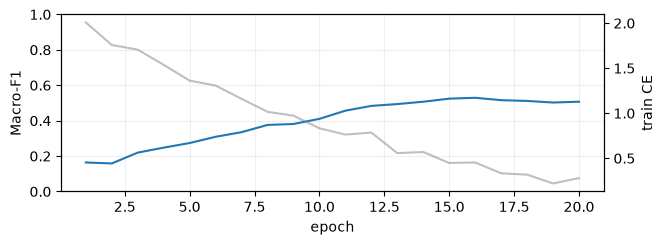

In [14]:
if TRAIN:
    from src.viewpoint_training import fit
    fit(ROOT, 'small', 'O', 43)
run_display(ROOT, 'small_O', 43)

### large · O · seed 43

| config | seed | status | epochs | best_epoch | val_macro_f1 | val_accuracy |
| --- | --- | --- | --- | --- | --- | --- |
| large_O | 43 | complete | 20 | 18 | 0.6330 | 0.6283 |

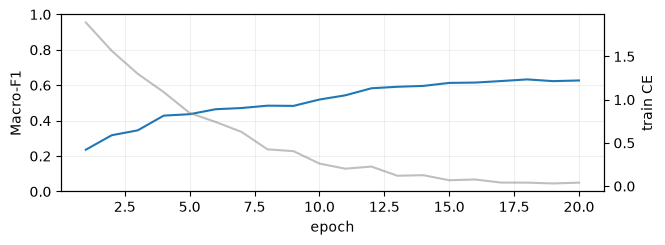

In [15]:
if TRAIN:
    from src.viewpoint_training import fit
    fit(ROOT, 'large', 'O', 43)
run_display(ROOT, 'large_O', 43)

### small · R · seed 43

| config | seed | status | epochs | best_epoch | val_macro_f1 | val_accuracy |
| --- | --- | --- | --- | --- | --- | --- |
| small_R | 43 | complete | 20 | 18 | 0.6141 | 0.6549 |

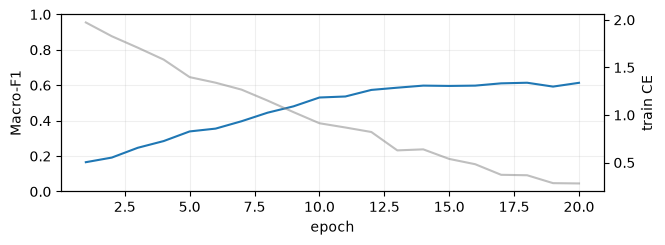

In [16]:
if TRAIN:
    from src.viewpoint_training import fit
    fit(ROOT, 'small', 'R', 43)
run_display(ROOT, 'small_R', 43)

### large · R · seed 43

| config | seed | status | epochs | best_epoch | val_macro_f1 | val_accuracy |
| --- | --- | --- | --- | --- | --- | --- |
| large_R | 43 | complete | 20 | 20 | 0.7116 | 0.7345 |

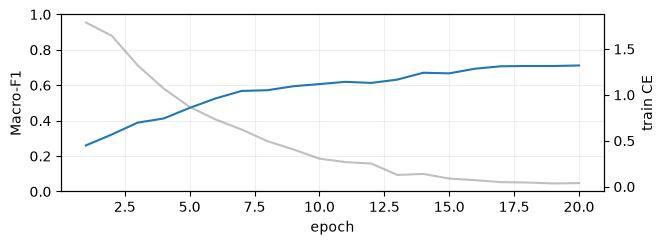

In [17]:
if TRAIN:
    from src.viewpoint_training import fit
    fit(ROOT, 'large', 'R', 43)
run_display(ROOT, 'large_R', 43)

## 🧪 Seed 44 — основной план

### small · O · seed 44

| config | seed | status | epochs | best_epoch | val_macro_f1 | val_accuracy |
| --- | --- | --- | --- | --- | --- | --- |
| small_O | 44 | complete | 20 | 20 | 0.5491 | 0.5752 |

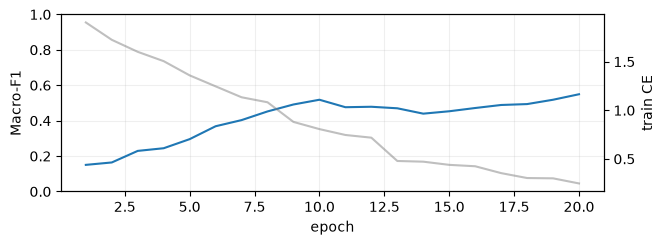

In [18]:
if TRAIN:
    from src.viewpoint_training import fit
    fit(ROOT, 'small', 'O', 44)
run_display(ROOT, 'small_O', 44)

### large · O · seed 44

| config | seed | status | epochs | best_epoch | val_macro_f1 | val_accuracy |
| --- | --- | --- | --- | --- | --- | --- |
| large_O | 44 | complete | 20 | 18 | 0.6178 | 0.5841 |

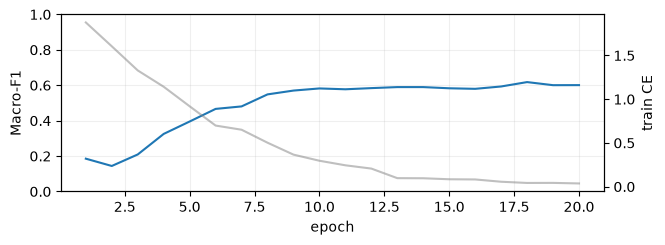

In [19]:
if TRAIN:
    from src.viewpoint_training import fit
    fit(ROOT, 'large', 'O', 44)
run_display(ROOT, 'large_O', 44)

### small · R · seed 44

| config | seed | status | epochs | best_epoch | val_macro_f1 | val_accuracy |
| --- | --- | --- | --- | --- | --- | --- |
| small_R | 44 | complete | 20 | 19 | 0.6522 | 0.6637 |

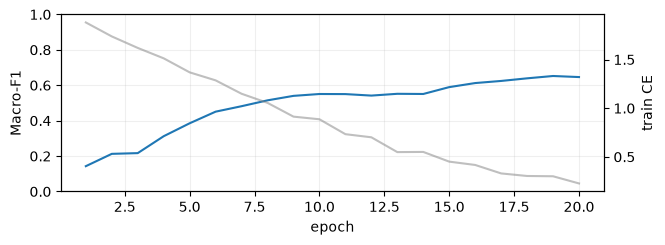

In [20]:
if TRAIN:
    from src.viewpoint_training import fit
    fit(ROOT, 'small', 'R', 44)
run_display(ROOT, 'small_R', 44)

### large · R · seed 44

| config | seed | status | epochs | best_epoch | val_macro_f1 | val_accuracy |
| --- | --- | --- | --- | --- | --- | --- |
| large_R | 44 | complete | 20 | 10 | 0.6209 | 0.6106 |

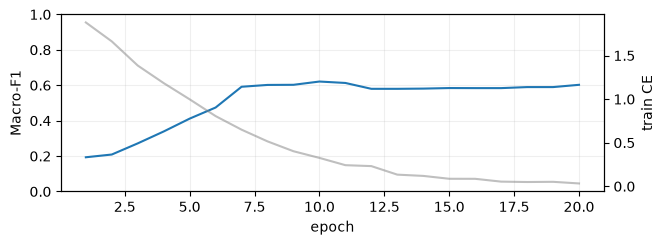

In [21]:
if TRAIN:
    from src.viewpoint_training import fit
    fit(ROOT, 'large', 'R', 44)
run_display(ROOT, 'large_R', 44)

---
## 📊 Общая оценка после всех 12 обучений

Все модели оцениваются на одном внутреннем test. Ниже — фактические результаты из CSV.
Полный mapping сохраняется при расчёте метрик срезов. SD: ddof=1 по трём seeds.

In [22]:
show_csv(REPORT / 'test_metrics.csv', ['config','seed','best_epoch','macro_f1','accuracy','images'])
show_csv(REPORT / 'test_summary.csv')

| config | seed | best_epoch | macro_f1 | accuracy | images |
| --- | --- | --- | --- | --- | --- |
| small_O | 42 | 18 | 0.3955 | 0.4605 | 367 |
| small_O | 43 | 16 | 0.5176 | 0.5722 | 367 |
| small_O | 44 | 20 | 0.4558 | 0.5068 | 367 |
| large_O | 42 | 14 | 0.4875 | 0.5504 | 367 |
| large_O | 43 | 18 | 0.5017 | 0.5422 | 367 |
| large_O | 44 | 18 | 0.5580 | 0.5531 | 367 |
| small_R | 42 | 19 | 0.4315 | 0.5232 | 367 |
| small_R | 43 | 18 | 0.5521 | 0.6213 | 367 |
| small_R | 44 | 19 | 0.5288 | 0.5477 | 367 |
| large_R | 42 | 19 | 0.6092 | 0.6621 | 367 |
| large_R | 43 | 20 | 0.6318 | 0.6866 | 367 |
| large_R | 44 | 10 | 0.5775 | 0.6567 | 367 |

| config | runs | macro_f1_mean | macro_f1_sample_SD | accuracy_mean | accuracy_sample_SD |
| --- | --- | --- | --- | --- | --- |
| small_O | 3 | 0.4563 | 0.0610 | 0.5132 | 0.0561 |
| large_O | 3 | 0.5158 | 0.0373 | 0.5486 | 0.0057 |
| small_R | 3 | 0.5041 | 0.0640 | 0.5640 | 0.0510 |
| large_R | 3 | 0.6062 | 0.0272 | 0.6685 | 0.0160 |

| class_index | poi_id |
| --- | --- |
| 0 | moscow/arbat/arseny_morozov_house |
| 1 | moscow/ostankinskiy/armenia |
| 2 | moscow/ostankinskiy/central_pavilion |
| 3 | moscow/ostankinskiy/cosmos |
| 4 | moscow/ostankinskiy/kazakhstan_pavilion |
| 5 | moscow/ostankinskiy/moldova_pavilion |
| 6 | moscow/ostankinskiy/pavilion_71 |

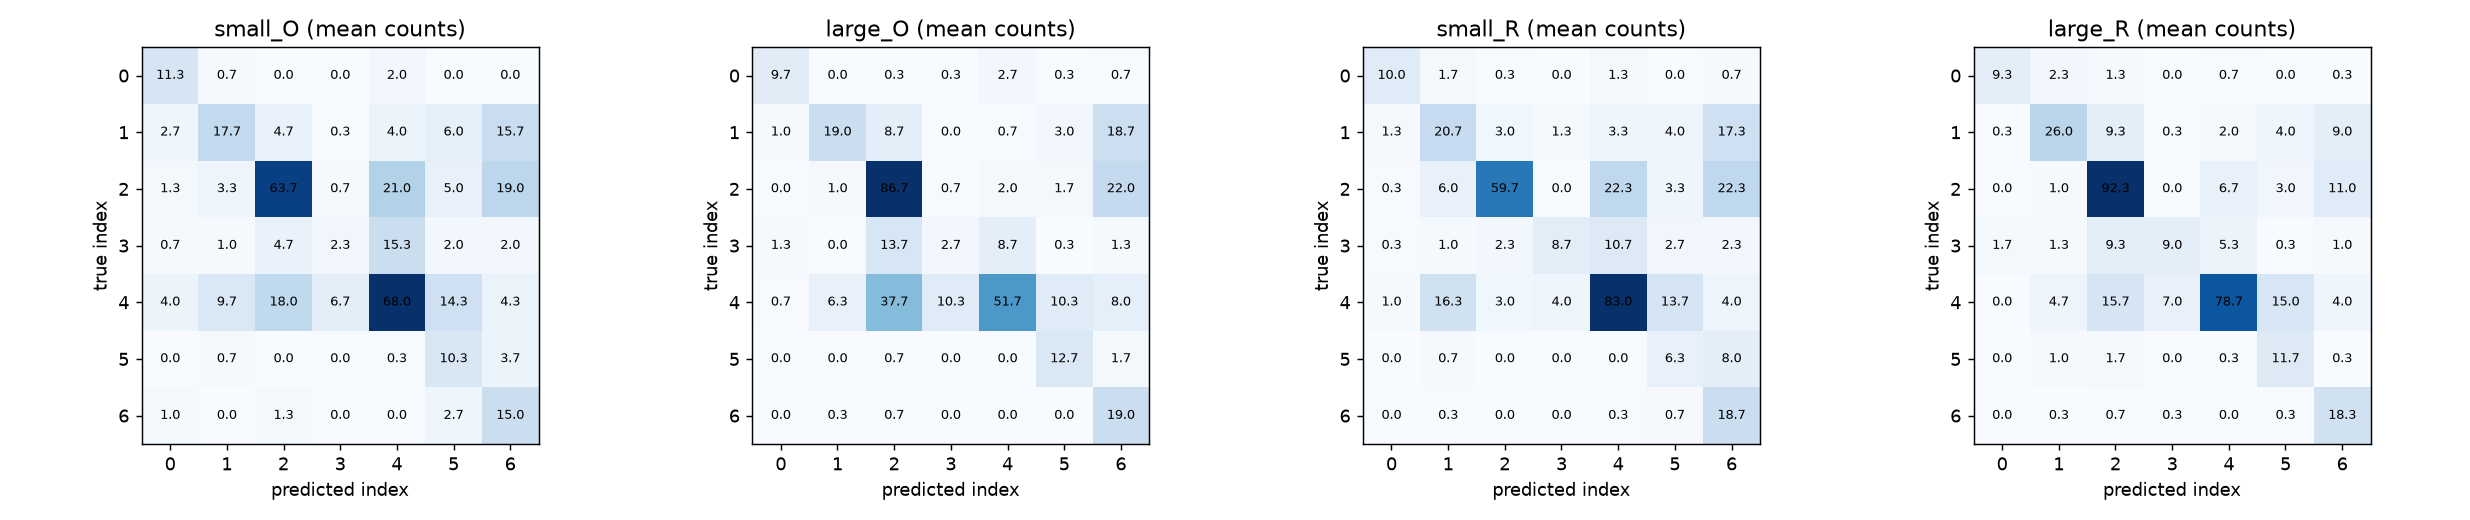

| config | seed | poi_id | support | f1 | recall |
| --- | --- | --- | --- | --- | --- |
| small_O | 42 | moscow/arbat/arseny_morozov_house | 14 | 0.6957 | 0.5714 |
| small_O | 42 | moscow/ostankinskiy/armenia | 51 | 0.1786 | 0.0980 |
| small_O | 42 | moscow/ostankinskiy/central_pavilion | 114 | 0.5625 | 0.4737 |
| small_O | 42 | moscow/ostankinskiy/cosmos | 28 | 0.0526 | 0.0357 |
| small_O | 42 | moscow/ostankinskiy/kazakhstan_pavilion | 125 | 0.5627 | 0.5920 |
| small_O | 42 | moscow/ostankinskiy/moldova_pavilion | 15 | 0.2804 | 1.0000 |
| small_O | 42 | moscow/ostankinskiy/pavilion_71 | 20 | 0.4364 | 0.6000 |
| small_O | 43 | moscow/arbat/arseny_morozov_house | 14 | 0.6222 | 1.0000 |
| small_O | 43 | moscow/ostankinskiy/armenia | 51 | 0.5676 | 0.4118 |
| small_O | 43 | moscow/ostankinskiy/central_pavilion | 114 | 0.6514 | 0.6228 |
| small_O | 43 | moscow/ostankinskiy/cosmos | 28 | 0.1860 | 0.1429 |
| small_O | 43 | moscow/ostankinskiy/kazakhstan_pavilion | 125 | 0.6122 | 0.6000 |
| small_O | 43 | moscow/ostankinskiy/moldova_pavilion | 15 | 0.5946 | 0.7333 |
| small_O | 43 | moscow/ostankinskiy/pavilion_71 | 20 | 0.3889 | 0.7000 |
| small_O | 44 | moscow/arbat/arseny_morozov_house | 14 | 0.6486 | 0.8571 |
| small_O | 44 | moscow/ostankinskiy/armenia | 51 | 0.4426 | 0.5294 |
| small_O | 44 | moscow/ostankinskiy/central_pavilion | 114 | 0.6316 | 0.5789 |
| small_O | 44 | moscow/ostankinskiy/cosmos | 28 | 0.1212 | 0.0714 |
| small_O | 44 | moscow/ostankinskiy/kazakhstan_pavilion | 125 | 0.5528 | 0.4400 |
| small_O | 44 | moscow/ostankinskiy/moldova_pavilion | 15 | 0.4545 | 0.3333 |
| small_O | 44 | moscow/ostankinskiy/pavilion_71 | 20 | 0.3393 | 0.9500 |
| large_O | 42 | moscow/arbat/arseny_morozov_house | 14 | 0.6154 | 0.5714 |
| large_O | 42 | moscow/ostankinskiy/armenia | 51 | 0.5195 | 0.3922 |
| large_O | 42 | moscow/ostankinskiy/central_pavilion | 114 | 0.6332 | 0.8860 |
| large_O | 42 | moscow/ostankinskiy/cosmos | 28 | 0.0000 | 0.0000 |
| large_O | 42 | moscow/ostankinskiy/kazakhstan_pavilion | 125 | 0.4686 | 0.3280 |
| large_O | 42 | moscow/ostankinskiy/moldova_pavilion | 15 | 0.5532 | 0.8667 |
| large_O | 42 | moscow/ostankinskiy/pavilion_71 | 20 | 0.6230 | 0.9500 |
| large_O | 43 | moscow/arbat/arseny_morozov_house | 14 | 0.6923 | 0.6429 |
| large_O | 43 | moscow/ostankinskiy/armenia | 51 | 0.5753 | 0.4118 |
| large_O | 43 | moscow/ostankinskiy/central_pavilion | 114 | 0.6816 | 0.6667 |
| large_O | 43 | moscow/ostankinskiy/cosmos | 28 | 0.1538 | 0.1429 |
| large_O | 43 | moscow/ostankinskiy/kazakhstan_pavilion | 125 | 0.5600 | 0.4480 |
| large_O | 43 | moscow/ostankinskiy/moldova_pavilion | 15 | 0.4643 | 0.8667 |
| large_O | 43 | moscow/ostankinskiy/pavilion_71 | 20 | 0.3846 | 1.0000 |
| large_O | 44 | moscow/arbat/arseny_morozov_house | 14 | 0.8571 | 0.8571 |
| large_O | 44 | moscow/ostankinskiy/armenia | 51 | 0.3855 | 0.3137 |
| large_O | 44 | moscow/ostankinskiy/central_pavilion | 114 | 0.6776 | 0.7281 |
| large_O | 44 | moscow/ostankinskiy/cosmos | 28 | 0.1778 | 0.1429 |
| large_O | 44 | moscow/ostankinskiy/kazakhstan_pavilion | 125 | 0.5888 | 0.4640 |
| large_O | 44 | moscow/ostankinskiy/moldova_pavilion | 15 | 0.8889 | 0.8000 |
| large_O | 44 | moscow/ostankinskiy/pavilion_71 | 20 | 0.3303 | 0.9000 |
| small_R | 42 | moscow/arbat/arseny_morozov_house | 14 | 0.7826 | 0.6429 |
| small_R | 42 | moscow/ostankinskiy/armenia | 51 | 0.0000 | 0.0000 |
| small_R | 42 | moscow/ostankinskiy/central_pavilion | 114 | 0.6230 | 0.5000 |
| small_R | 42 | moscow/ostankinskiy/cosmos | 28 | 0.2222 | 0.1429 |
| small_R | 42 | moscow/ostankinskiy/kazakhstan_pavilion | 125 | 0.6596 | 0.7440 |
| small_R | 42 | moscow/ostankinskiy/moldova_pavilion | 15 | 0.2716 | 0.7333 |
| small_R | 42 | moscow/ostankinskiy/pavilion_71 | 20 | 0.4615 | 0.9000 |
| small_R | 43 | moscow/arbat/arseny_morozov_house | 14 | 0.7097 | 0.7857 |
| small_R | 43 | moscow/ostankinskiy/armenia | 51 | 0.6444 | 0.5686 |
| small_R | 43 | moscow/ostankinskiy/central_pavilion | 114 | 0.7047 | 0.5965 |
| small_R | 43 | moscow/ostankinskiy/cosmos | 28 | 0.4615 | 0.4286 |
| small_R | 43 | moscow/ostankinskiy/kazakhstan_pavilion | 125 | 0.7020 | 0.6880 |
| small_R | 43 | moscow/ostankinskiy/moldova_pavilion | 15 | 0.2424 | 0.2667 |
| small_R | 43 | moscow/ostankinskiy/pavilion_71 | 20 | 0.4000 | 0.9000 |
| small_R | 44 | moscow/arbat/arseny_morozov_house | 14 | 0.7407 | 0.7143 |
| small_R | 44 | moscow/ostankinskiy/armenia | 51 | 0.4342 | 0.6471 |
| small_R | 44 | moscow/ostankinskiy/central_pavilion | 114 | 0.6316 | 0.4737 |
| small_R | 44 | moscow/ostankinskiy/cosmos | 28 | 0.5263 | 0.3571 |
| small_R | 44 | moscow/ostankinskiy/kazakhstan_pavilion | 125 | 0.6635 | 0.5600 |
| small_R | 44 | moscow/ostankinskiy/moldova_pavilion | 15 | 0.3478 | 0.2667 |
| small_R | 44 | moscow/ostankinskiy/pavilion_71 | 20 | 0.3571 | 1.0000 |
| large_R | 42 | moscow/arbat/arseny_morozov_house | 14 | 0.8000 | 0.7143 |
| large_R | 42 | moscow/ostankinskiy/armenia | 51 | 0.4286 | 0.2941 |
| large_R | 42 | moscow/ostankinskiy/central_pavilion | 114 | 0.7416 | 0.8684 |
| large_R | 42 | moscow/ostankinskiy/cosmos | 28 | 0.4681 | 0.3929 |
| large_R | 42 | moscow/ostankinskiy/kazakhstan_pavilion | 125 | 0.7308 | 0.6080 |
| large_R | 42 | moscow/ostankinskiy/moldova_pavilion | 15 | 0.4746 | 0.9333 |
| large_R | 42 | moscow/ostankinskiy/pavilion_71 | 20 | 0.6207 | 0.9000 |
| large_R | 43 | moscow/arbat/arseny_morozov_house | 14 | 0.7143 | 0.7143 |
| large_R | 43 | moscow/ostankinskiy/armenia | 51 | 0.7835 | 0.7451 |
| large_R | 43 | moscow/ostankinskiy/central_pavilion | 114 | 0.7981 | 0.7456 |
| large_R | 43 | moscow/ostankinskiy/cosmos | 28 | 0.3529 | 0.3214 |
| large_R | 43 | moscow/ostankinskiy/kazakhstan_pavilion | 125 | 0.6941 | 0.6080 |
| large_R | 43 | moscow/ostankinskiy/moldova_pavilion | 15 | 0.4762 | 1.0000 |
| large_R | 43 | moscow/ostankinskiy/pavilion_71 | 20 | 0.6032 | 0.9500 |
| large_R | 44 | moscow/arbat/arseny_morozov_house | 14 | 0.6957 | 0.5714 |
| large_R | 44 | moscow/ostankinskiy/armenia | 51 | 0.5208 | 0.4902 |
| large_R | 44 | moscow/ostankinskiy/central_pavilion | 114 | 0.7352 | 0.8158 |
| large_R | 44 | moscow/ostankinskiy/cosmos | 28 | 0.3889 | 0.2500 |
| large_R | 44 | moscow/ostankinskiy/kazakhstan_pavilion | 125 | 0.7336 | 0.6720 |
| large_R | 44 | moscow/ostankinskiy/moldova_pavilion | 15 | 0.4615 | 0.4000 |
| large_R | 44 | moscow/ostankinskiy/pavilion_71 | 20 | 0.5070 | 0.9000 |

In [23]:
mapping=json.loads((DATA/'class_mapping.json').read_text(encoding='utf-8'))
display(Markdown(table([{'class_index':index,'poi_id':poi} for poi,index in mapping.items()])))
display(Image(filename=str(REPORT/'figures/confusion_matrices.png')))
show_csv(REPORT / 'per_poi_metrics.csv', ['config','seed','poi_id','support','f1','recall'])

In [24]:
show_csv(REPORT / 'viewpoint_slices.csv', ['config','seed','viewpoint','images','macro_f1','accuracy','mapping_classes'])

| config | seed | viewpoint | images | macro_f1 | accuracy | mapping_classes |
| --- | --- | --- | --- | --- | --- | --- |
| small_O | 42 | main | 133 | 0.5077 | 0.5714 | 7 |
| small_O | 42 | left | 36 | 0.3896 | 0.6389 | 7 |
| small_O | 42 | right | 66 | 0.5004 | 0.6212 | 7 |
| small_O | 42 | undetermined | 132 | 0.2178 | 0.2197 | 7 |
| small_O | 43 | main | 133 | 0.6701 | 0.6391 | 7 |
| small_O | 43 | left | 36 | 0.6815 | 0.8056 | 7 |
| small_O | 43 | right | 66 | 0.5269 | 0.6515 | 7 |
| small_O | 43 | undetermined | 132 | 0.2467 | 0.4015 | 7 |
| small_O | 44 | main | 133 | 0.6150 | 0.6090 | 7 |
| small_O | 44 | left | 36 | 0.4254 | 0.6389 | 7 |
| small_O | 44 | right | 66 | 0.5048 | 0.7273 | 7 |
| small_O | 44 | undetermined | 132 | 0.1737 | 0.2576 | 7 |
| large_O | 42 | main | 133 | 0.6712 | 0.7744 | 7 |
| large_O | 42 | left | 36 | 0.4653 | 0.5833 | 7 |
| large_O | 42 | right | 66 | 0.5284 | 0.5606 | 7 |
| large_O | 42 | undetermined | 132 | 0.1032 | 0.3106 | 7 |
| large_O | 43 | main | 133 | 0.7043 | 0.7068 | 7 |
| large_O | 43 | left | 36 | 0.6059 | 0.6944 | 7 |
| large_O | 43 | right | 66 | 0.4279 | 0.5606 | 7 |
| large_O | 43 | undetermined | 132 | 0.1954 | 0.3258 | 7 |
| large_O | 44 | main | 133 | 0.6749 | 0.6767 | 7 |
| large_O | 44 | left | 36 | 0.6066 | 0.7500 | 7 |
| large_O | 44 | right | 66 | 0.5970 | 0.5909 | 7 |
| large_O | 44 | undetermined | 132 | 0.2448 | 0.3561 | 7 |
| small_R | 42 | main | 133 | 0.5662 | 0.5940 | 7 |
| small_R | 42 | left | 36 | 0.7197 | 0.8333 | 7 |
| small_R | 42 | right | 66 | 0.4687 | 0.6364 | 7 |
| small_R | 42 | undetermined | 132 | 0.1500 | 0.3106 | 7 |
| small_R | 43 | main | 133 | 0.6612 | 0.6992 | 7 |
| small_R | 43 | left | 36 | 0.6308 | 0.8333 | 7 |
| small_R | 43 | right | 66 | 0.5874 | 0.8182 | 7 |
| small_R | 43 | undetermined | 132 | 0.2510 | 0.3864 | 7 |
| small_R | 44 | main | 133 | 0.6153 | 0.6165 | 7 |
| small_R | 44 | left | 36 | 0.6447 | 0.8056 | 7 |
| small_R | 44 | right | 66 | 0.6918 | 0.7727 | 7 |
| small_R | 44 | undetermined | 132 | 0.2342 | 0.2955 | 7 |
| large_R | 42 | main | 133 | 0.6887 | 0.7293 | 7 |
| large_R | 42 | left | 36 | 0.7419 | 0.9167 | 7 |
| large_R | 42 | right | 66 | 0.7205 | 0.7121 | 7 |
| large_R | 42 | undetermined | 132 | 0.3642 | 0.5000 | 7 |
| large_R | 43 | main | 133 | 0.8552 | 0.8797 | 7 |
| large_R | 43 | left | 36 | 0.7453 | 0.8889 | 7 |
| large_R | 43 | right | 66 | 0.8014 | 0.8636 | 7 |
| large_R | 43 | undetermined | 132 | 0.2086 | 0.3485 | 7 |
| large_R | 44 | main | 133 | 0.7153 | 0.7820 | 7 |
| large_R | 44 | left | 36 | 0.6087 | 0.7500 | 7 |
| large_R | 44 | right | 66 | 0.7236 | 0.7121 | 7 |
| large_R | 44 | undetermined | 132 | 0.2866 | 0.4773 | 7 |

### Статистическая методика

Предусмотрены 5000 парных кластерных повторов, seed2026, двусторонние 95% интервалы.
Общие outings учитываются совместно, сеансы — внутри фиксированного POI.
При неизвестной истории сеансов схема может быть недопустима: интервалы тогда
не рассчитываются и не заменяются bootstrap отдельных кадров. Test исторический;
статус исследования — поисковый внутренний.

In [25]:
result=json.loads((REPORT/'inference.json').read_text(encoding='utf-8'))
point=result['point']
display(Markdown(table([{'metric':key,'value_pp':100*point[key]} for key in ['G_O','G_R','C','small_gain','large_gain']])))
show_csv(REPORT/'per_seed_contrasts.csv')
display(Markdown(table([{'bootstrap_requested':result['requested_replicates'],'performed':result['performed_replicates'],'C_ci95':result['C_ci95'],'G_R_ci95':result['G_R_ci95'],'decision':result['conclusion']}])))
show_json(DATA/'bootstrap_plan_before_predictions.json')
show_json(REPORT/'inference.json')

| metric | value_pp |
| --- | --- |
| G_O | 5.9448 |
| G_R | 10.2033 |
| C | -4.2585 |
| small_gain | 4.7818 |
| large_gain | 9.0404 |

| G_O | G_R | C | small_gain | large_gain | seed |
| --- | --- | --- | --- | --- | --- |
| 0.0920 | 0.1777 | -0.0857 | 0.0360 | 0.1216 | 42 |
| -0.0158 | 0.0796 | -0.0955 | 0.0345 | 0.1300 | 43 |
| 0.1022 | 0.0488 | 0.0534 | 0.0730 | 0.0195 | 44 |

| bootstrap_requested | performed | C_ci95 | G_R_ci95 | decision |
| --- | --- | --- | --- | --- |
| 5000 | 0 | None | None | inconclusive_missing_session_history |

### 💻 Ресурсы

Заранее выбранная пара Р/42: Windows CPU FP32,20 прогревов,100 замеров×3.
Это только forward; не Android, не экспорт и не полный путь обработки JPEG.

In [26]:
show_csv(REPORT/'resource_benchmark.csv')

| architecture | mode | seed | repeat | p50_ms | p95_ms | model_bytes | parameters | device | dtype | batch_size | threads | warmups | measurements | scope |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| small | R | 42 | 1 | 12.0402 | 14.8891 | 6230039 | 1525031 | Windows CPU; not Android | float32 | 1 | 4 | 20 | 100 | torch forward only; excludes JPEG/preprocessing; no mobile export measured |
| small | R | 42 | 2 | 11.0494 | 12.7153 | 6230039 | 1525031 | Windows CPU; not Android | float32 | 1 | 4 | 20 | 100 | torch forward only; excludes JPEG/preprocessing; no mobile export measured |
| small | R | 42 | 3 | 10.9494 | 11.9648 | 6230039 | 1525031 | Windows CPU; not Android | float32 | 1 | 4 | 20 | 100 | torch forward only; excludes JPEG/preprocessing; no mobile export measured |
| large | R | 42 | 1 | 22.1159 | 27.7489 | 17044559 | 4210999 | Windows CPU; not Android | float32 | 1 | 4 | 20 | 100 | torch forward only; excludes JPEG/preprocessing; no mobile export measured |
| large | R | 42 | 2 | 20.6111 | 22.7596 | 17044559 | 4210999 | Windows CPU; not Android | float32 | 1 | 4 | 20 | 100 | torch forward only; excludes JPEG/preprocessing; no mobile export measured |
| large | R | 42 | 3 | 21.2084 | 24.3853 | 17044559 | 4210999 | Windows CPU; not Android | float32 | 1 | 4 | 20 | 100 | torch forward only; excludes JPEG/preprocessing; no mobile export measured |

## 🧭 Итог по гипотезе

In [27]:
text=(REPORT/'research_summary.md').read_text(encoding='utf-8')
display(Markdown(text.split('## Вывод по гипотезе')[1].split('## Практический выбор')[0]))
show_json(REPORT/'experiment_status.json')



В точечных оценках разрыв Large − Small увеличился на 4.26 п.п. Качество Small выросло на 4.78 п.п., Large выросло на 9.04 п.п. На Р подписанный разрыв составляет 10.20 п.п. Два рабочих порога по одним точечным оценкам не выполнены; решение по протоколу требует интервалов.

**Гипотеза не подтверждена:** без допустимых доверительных интервалов нельзя проверить
совместные условия lower95(C)≥0.03 и upper95(GР)≤0.03.
Точечные результаты выше описывают фактически обученные модели; отсутствие подтверждения
не означает доказанного отсутствия эффекта. Изменение качества Small и Large показано
раздельно: сокращение разрыва из-за падения Large не считается улучшением Small.



## 🔁 Как воспроизвести

Из корня проекта: `python scripts/run_viewpoint_research.py pilot`, затем после
зафиксированного development-решения `main`, затем `evaluate`.
Повторное обучение после открытия test запрещено для этого run_id. Для нового рецепта
нужен новый run_id и новый снимок данных. По умолчанию ноутбук читает готовые артефакты.
Подробный отчёт: `reports/viewpoint_20261102_v1/research_summary.md`.
Отказ на чужих фото и мобильная готовность этим экспериментом не доказываются.

### 📎 Исходные таблицы

- [Manifests О/Р и общие val/test](../data/annotations/viewpoint_20261102_v1/manifests/)
- [Разметка и решения об отборе](../data/annotations/viewpoint_20261102_v1/selection_decisions.csv)
- [Карточки ракурсов](../data/annotations/viewpoint_20261102_v1/orientation_cards.json)
- [Все 12 результатов](../reports/viewpoint_20261102_v1/test_metrics.csv)
- [Предсказания по каждому кадру](../reports/viewpoint_20261102_v1/test_predictions.csv)
- [Краткий отчёт](../reports/viewpoint_20261102_v1/research_summary.md)
